# Báo Cáo Thực Nghiệm: Mạng Tích Chập 1D (1D CNN) Thuần NumPy Từ Đầu
## Bài Toán: Dự Đoán Nguy Cơ Tiểu Đường (Biomedical Tabular Classification)
**Học phần:** Phát triển Hệ thống Thông minh (Intelligent System Development)  
**Nhiệm vụ:** Assignment 04 - Xây dựng mô hình 1D CNN thuần từ đầu không dùng thư viện Deep Learning  
**Dữ liệu:** `diabetes_prediction_dataset.csv` (100,000 mẫu lâm sàng)


In [1]:
import os
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# Cấu hình hạt giống ngẫu nhiên để tái lập thực nghiệm có kiểm soát
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 11


### 1. Đọc Dữ Liệu & Khảo Sát Cấu Trúc Ban Đầu
Tập dữ liệu dự đoán nguy cơ tiểu đường gồm 100,000 hồ sơ bệnh nhân với 8 biến đặc trưng nhân khẩu học & xét nghiệm lâm sàng.


In [2]:
DATA_PATH = "../../../Assigment 02/diabetes/data/diabetes_prediction_dataset.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "src/Assigment 02/diabetes/data/diabetes_prediction_dataset.csv"

df_raw = pd.read_csv(DATA_PATH)
print(f"Kích thước tập dữ liệu thô: {df_raw.shape[0]:,} dòng, {df_raw.shape[1]} cột")
df_raw.head()


Kích thước tập dữ liệu thô: 100,000 dòng, 9 cột


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


### 2. Quy Trình Tiền Xử Lý & Làm Sạch Dữ Liệu
1. Khử trùng lặp bản ghi.
2. Mã hóa biến phân loại: `gender` (One-hot/Binary), `smoking_history` (Ordinal mapping).
3. Đảm bảo đúng **8 biến đặc trưng chuẩn** theo Slide 7 & 10 của bài giảng:
   `[gender, age, hypertension, heart_disease, smoking_history, bmi, HbA1c_level, blood_glucose_level]`.


In [3]:
# Khử trùng lặp
n_dups = df_raw.duplicated().sum()
df_dedup = df_raw.drop_duplicates().copy()
print(f"Số bản ghi trùng lặp đã loại bỏ: {n_dups:,} dòng")

# Làm sạch gender
df_clean = df_dedup[df_dedup['gender'] != 'Other'].copy()
df_clean['gender'] = (df_clean['gender'] == 'Male').astype(int)

# Mã hóa smoking_history
smoking_map = {
    'never': 0, 'No Info': 0,
    'former': 1, 'not current': 1,
    'current': 2, 'ever': 2
}
df_clean['smoking_history'] = df_clean['smoking_history'].map(smoking_map).fillna(0).astype(int)

features = ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level']
target = 'diabetes'

X_data = df_clean[features].values.astype(np.float32)
y_data = df_clean[target].values.astype(np.float32)

print(f"Tập dữ liệu sau làm sạch: {X_data.shape[0]:,} mẫu, {X_data.shape[1]} đặc trưng lâm sàng.")


Số bản ghi trùng lặp đã loại bỏ: 3,854 dòng
Tập dữ liệu sau làm sạch: 96,128 mẫu, 8 đặc trưng lâm sàng.


### 3. Phân Chia Dữ Liệu & Chuẩn Hóa Đặc Trưng
- Chia tỷ lệ Train/Test: 80% / 20% phân tầng (`stratify=y`) với `random_state=42`.
- Chuẩn hóa bằng `StandardScaler` (fit trên tập Train, transform trên tập Test để chống rò rỉ dữ liệu).
- Chuyển đổi định dạng phù hợp với 1D CNN: `(batch_size, in_channels=1, length=8)`.


In [4]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.20, random_state=RANDOM_SEED, stratify=y_data
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

# Chuyển đổi sang dạng 3D cho 1D CNN: (N, C_in=1, L=8)
X_train = X_train_scaled[:, np.newaxis, :]
X_test = X_test_scaled[:, np.newaxis, :]

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape : {X_test.shape}, y_test shape : {y_test.shape}")


X_train shape: (76902, 1, 8), y_train shape: (76902,)
X_test shape : (19226, 1, 8), y_test shape : (19226,)


### 4. Triển Khai Toàn Bộ Các Lớp 1D CNN Thuần Từ Đầu (NumPy From Scratch)
Dưới đây là cài đặt chi tiết toàn bộ các lớp tích chập, gom mẫu, kích hoạt, kết nối đầy đủ và bộ tối ưu hóa Adam theo đúng toán học trong Bài giảng số 4:
1. **`Conv1D`**: Phép tích chập 1D qua các kênh đầu vào bằng kỹ thuật `sliding_window_view` và `np.einsum`, tính đạo hàm giải tích `dW`, `db`, `dX`.
2. **`MaxPool1D`**: Gom mẫu cực đại 1 chiều và truyền ngược gradient qua mặt nạ argmax.
3. **`ReLU`, `Flatten`, `Dense`, `Sigmoid`**: Các khối hàm kích hoạt, trải phẳng và tuyến tính.
4. **`Sequential1DCNN`**: Container quản lý luồng lan truyền xuôi và lan truyền ngược.
5. **`AdamOptimizer`**: Thuật toán tối ưu hóa thích nghi bậc 1 và bậc 2 (Adaptive Moment Estimation).
6. **`binary_cross_entropy`**: Hàm mất mát Binary Cross Entropy và đạo hàm cho bài toán phân loại nhị phân.


In [5]:
# =====================================================================
# 1. CÀI ĐẶT CÁC LỚP MẠNG 1D CNN THUẦN TỪ ĐẦU BẰNG NUMPY
# =====================================================================

class Conv1D:
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=0):
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.kernel_size = kernel_size
        self.stride = stride
        self.padding = padding

        # Khởi tạo He (Kaiming) Normal
        limit = np.sqrt(2.0 / (in_channels * kernel_size))
        self.W = np.random.randn(out_channels, in_channels, kernel_size).astype(np.float32) * limit
        self.b = np.zeros(out_channels, dtype=np.float32)

        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)
        self.X = None
        self.sub_windows = None

    def forward(self, X):
        # X shape: (batch_size, in_channels, length)
        # Output shape: (batch_size, out_channels, length_out)
        self.X = X
        batch_size, in_channels, length = X.shape
        assert in_channels == self.in_channels, f"Expected {self.in_channels} channels, got {in_channels}"

        if self.padding > 0:
            X_pad = np.pad(X, ((0, 0), (0, 0), (self.padding, self.padding)), mode='constant')
        else:
            X_pad = X

        # Sử dụng sliding_window_view vector hóa tối đa
        self.sub_windows = np.lib.stride_tricks.sliding_window_view(
            X_pad, window_shape=self.kernel_size, axis=-1
        )[:, :, ::self.stride, :]

        # Einsum: N: batch, C: in_channels, L: out_len, K: kernel_size; F: out_channels
        out = np.einsum('nclk,fck->nfl', self.sub_windows, self.W) + self.b[:, None]
        return out

    def backward(self, dZ):
        # dZ shape: (batch_size, out_channels, length_out)
        # Returns dX shape: (batch_size, in_channels, length)
        self.db = np.sum(dZ, axis=(0, 2))
        self.dW = np.einsum('nfl,nclk->fck', dZ, self.sub_windows)

        batch_size, in_channels, length = self.X.shape
        L_out = dZ.shape[2]
        dX = np.zeros_like(self.X)

        for k in range(self.kernel_size):
            dX[:, :, k:k + L_out] += np.einsum('nfl,fc->ncl', dZ, self.W[:, :, k])

        return dX


class MaxPool1D:
    def __init__(self, pool_size=2):
        self.pool_size = pool_size
        self.X_shape = None
        self.X_reshaped = None
        self.out = None

    def forward(self, X):
        self.X_shape = X.shape
        batch_size, channels, length = X.shape
        L_out = length // self.pool_size

        self.X_reshaped = X[:, :, :L_out * self.pool_size].reshape(
            batch_size, channels, L_out, self.pool_size
        )
        self.out = np.max(self.X_reshaped, axis=-1)
        return self.out

    def backward(self, dZ):
        batch_size, channels, L_out = dZ.shape
        argmax_mask = (self.X_reshaped == self.out[:, :, :, None])
        counts = np.sum(argmax_mask, axis=-1, keepdims=True)
        counts[counts == 0] = 1.0
        mask = argmax_mask / counts

        dX_reshaped = dZ[:, :, :, None] * mask
        dX = np.zeros(self.X_shape, dtype=dZ.dtype)
        dX[:, :, :L_out * self.pool_size] = dX_reshaped.reshape(
            batch_size, channels, L_out * self.pool_size
        )
        return dX


class ReLU:
    def __init__(self):
        self.X = None

    def forward(self, X):
        self.X = X
        return np.maximum(0, X)

    def backward(self, dZ):
        return dZ * (self.X > 0)


class Flatten:
    def __init__(self):
        self.orig_shape = None

    def forward(self, X):
        self.orig_shape = X.shape
        return X.reshape(X.shape[0], -1)

    def backward(self, dZ):
        return dZ.reshape(self.orig_shape)


class Dense:
    def __init__(self, in_features, out_features):
        self.in_features = in_features
        self.out_features = out_features

        limit = np.sqrt(2.0 / in_features)
        self.W = np.random.randn(in_features, out_features).astype(np.float32) * limit
        self.b = np.zeros(out_features, dtype=np.float32)

        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)
        self.X = None

    def forward(self, X):
        self.X = X
        return np.dot(X, self.W) + self.b

    def backward(self, dZ):
        self.db = np.sum(dZ, axis=0)
        self.dW = np.dot(self.X.T, dZ)
        return np.dot(dZ, self.W.T)


class Sigmoid:
    def __init__(self):
        self.out = None

    def forward(self, X):
        self.out = 1.0 / (1.0 + np.exp(-np.clip(X, -25.0, 25.0)))
        return self.out

    def backward(self, dZ):
        return dZ * self.out * (1.0 - self.out)


class Sequential1DCNN:
    def __init__(self, layers):
        self.layers = layers

    def forward(self, X):
        out = X
        for layer in self.layers:
            out = layer.forward(out)
        return out

    def backward(self, dLoss):
        grad = dLoss
        for layer in reversed(self.layers):
            grad = layer.backward(grad)
        return grad

    def get_trainable_layers(self):
        return [l for l in self.layers if hasattr(l, 'W')]


class AdamOptimizer:
    def __init__(self, trainable_layers, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        self.layers = trainable_layers
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.t = 0

        self.mW = [np.zeros_like(l.W) for l in self.layers]
        self.vW = [np.zeros_like(l.W) for l in self.layers]
        self.mb = [np.zeros_like(l.b) if hasattr(l, 'b') else None for l in self.layers]
        self.vb = [np.zeros_like(l.b) if hasattr(l, 'b') else None for l in self.layers]

    def step(self):
        self.t += 1
        for i, layer in enumerate(self.layers):
            self.mW[i] = self.beta1 * self.mW[i] + (1 - self.beta1) * layer.dW
            self.vW[i] = self.beta2 * self.vW[i] + (1 - self.beta2) * (layer.dW ** 2)
            m_hat = self.mW[i] / (1 - self.beta1 ** self.t)
            v_hat = self.vW[i] / (1 - self.beta2 ** self.t)
            layer.W -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

            if hasattr(layer, 'b') and hasattr(layer, 'db'):
                self.mb[i] = self.beta1 * self.mb[i] + (1 - self.beta1) * layer.db
                self.vb[i] = self.beta2 * self.vb[i] + (1 - self.beta2) * (layer.db ** 2)
                m_hat_b = self.mb[i] / (1 - self.beta1 ** self.t)
                v_hat_b = self.vb[i] / (1 - self.beta2 ** self.t)
                layer.b -= self.lr * m_hat_b / (np.sqrt(v_hat_b) + self.eps)


def binary_cross_entropy(y_pred, y_true, eps=1e-7):
    y_pred = np.clip(y_pred, eps, 1.0 - eps)
    loss = -np.mean(y_true * np.log(y_pred) + (1.0 - y_true) * np.log(1.0 - y_pred))
    grad = (y_pred - y_true) / (y_pred * (1.0 - y_pred) * len(y_true))
    return loss, grad

print("Đã nạp toàn bộ các lớp 1D CNN thuần NumPy thành công!")


Đã nạp toàn bộ các lớp 1D CNN thuần NumPy thành công!


### 5. Khởi Tạo Kiến Trúc Mô Hình & Kiểm Tra Số Lượng Tham Số
Khởi tạo kiến trúc theo Slide 10:
`Input (1, 8) -> Conv1D(16, k=3) -> ReLU -> Conv1D(16, k=3) -> ReLU -> MaxPool1D(2) -> Flatten -> Dense(8) -> ReLU -> Dense(1) -> Sigmoid`.


In [6]:
model = Sequential1DCNN([
    Conv1D(in_channels=1, out_channels=16, kernel_size=3), # L_out = 8 - 3 + 1 = 6
    ReLU(),
    Conv1D(in_channels=16, out_channels=16, kernel_size=3), # L_out = 6 - 3 + 1 = 4
    ReLU(),
    MaxPool1D(pool_size=2),                                  # L_out = 4 // 2 = 2
    Flatten(),                                               # 16 * 2 = 32
    Dense(in_features=32, out_features=8),
    ReLU(),
    Dense(in_features=8, out_features=1),
    Sigmoid()
])

trainable_layers = model.get_trainable_layers()
total_params = sum(l.W.size + l.b.size for l in trainable_layers)
print(f"Tổng số tham số học được của mô hình 1D CNN NumPy: {total_params:,} tham số")


Tổng số tham số học được của mô hình 1D CNN NumPy: 1,121 tham số


### 5. Huấn Luyện Mô Hình Với Thuật Toán Tối Ưu Adam
Huấn luyện mô hình theo từng mini-batch trên toàn bộ tập huấn luyện Train set (76,905 mẫu).


In [7]:
optimizer = AdamOptimizer(trainable_layers, lr=0.003)
epochs = 12
batch_size = 256
n_samples = len(X_train)

history = {"loss": [], "val_loss": [], "val_acc": [], "val_f1": []}

start_time = time.time()
print("Bắt đầu huấn luyện mô hình 1D CNN NumPy From Scratch...")

for epoch in range(1, epochs + 1):
    indices = np.random.permutation(n_samples)
    X_shuffled = X_train[indices]
    y_shuffled = y_train[indices]
    
    epoch_losses = []
    for i in range(0, n_samples, batch_size):
        X_b = X_shuffled[i:i + batch_size]
        y_b = y_shuffled[i:i + batch_size, np.newaxis]
        
        # Forward pass
        preds = model.forward(X_b)
        loss, grad = binary_cross_entropy(preds, y_b)
        epoch_losses.append(loss)
        
        # Backward pass
        model.backward(grad)
        
        # Cập nhật trọng số
        optimizer.step()
        
    train_loss = np.mean(epoch_losses)
    
    # Đánh giá trên tập kiểm thử
    val_preds = model.forward(X_test).ravel()
    val_loss, _ = binary_cross_entropy(val_preds[:, np.newaxis], y_test[:, np.newaxis])
    val_binary = (val_preds >= 0.5).astype(int)
    val_acc = accuracy_score(y_test, val_binary)
    val_f1 = f1_score(y_test, val_binary, zero_division=0)
    
    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)
    
    print(f"Epoch {epoch:02d}/{epochs:02d} - Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Val F1: {val_f1:.4f}")

train_time = time.time() - start_time
print(f"\nHuấn luyện hoàn tất trong: {train_time:.2f} giây!")


Bắt đầu huấn luyện mô hình 1D CNN NumPy From Scratch...


Epoch 01/12 - Train Loss: 0.1346 | Val Loss: 0.1112 | Val Acc: 0.9615 | Val F1: 0.7474


Epoch 02/12 - Train Loss: 0.1067 | Val Loss: 0.1090 | Val Acc: 0.9605 | Val F1: 0.7552


Epoch 03/12 - Train Loss: 0.1030 | Val Loss: 0.1051 | Val Acc: 0.9637 | Val F1: 0.7501


Epoch 04/12 - Train Loss: 0.1003 | Val Loss: 0.1036 | Val Acc: 0.9638 | Val F1: 0.7626


Epoch 05/12 - Train Loss: 0.0980 | Val Loss: 0.1014 | Val Acc: 0.9632 | Val F1: 0.7698


... (3 outputs left out)

Epoch 09/12 - Train Loss: 0.0918 | Val Loss: 0.0974 | Val Acc: 0.9639 | Val F1: 0.7745


Epoch 10/12 - Train Loss: 0.0911 | Val Loss: 0.0941 | Val Acc: 0.9667 | Val F1: 0.7829


Epoch 11/12 - Train Loss: 0.0901 | Val Loss: 0.0918 | Val Acc: 0.9686 | Val F1: 0.7911


Epoch 12/12 - Train Loss: 0.0896 | Val Loss: 0.0915 | Val Acc: 0.9700 | Val F1: 0.8041

Huấn luyện hoàn tất trong: 67.22 giây!


### 6. Đánh Giá Toàn Diện & Trực Quan Hóa Kết Quả
Đo đạc các thang đo chính: Accuracy, Precision, Recall, F1-score, ROC-AUC và vẽ biểu đồ quá trình học.


=== KẾT QUẢ ĐÁNH GIÁ 1D CNN (NUMPY FROM SCRATCH) ===
• Accuracy : 0.9700
• Precision: 0.9502
• Recall   : 0.6969
• F1-Score : 0.8041
• ROC-AUC  : 0.9728
• Thời gian: 67.22 giây


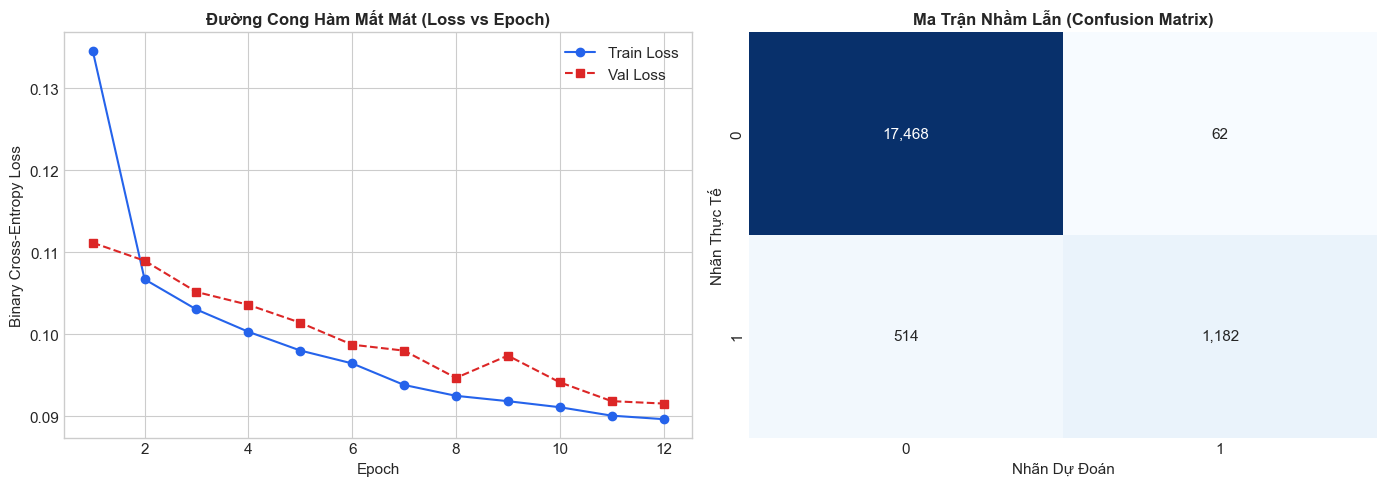

In [8]:
# Dự đoán trên tập kiểm thử
y_prob = model.forward(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

print(f"=== KẾT QUẢ ĐÁNH GIÁ 1D CNN (NUMPY FROM SCRATCH) ===")
print(f"• Accuracy : {acc:.4f}")
print(f"• Precision: {prec:.4f}")
print(f"• Recall   : {rec:.4f}")
print(f"• F1-Score : {f1:.4f}")
print(f"• ROC-AUC  : {auc:.4f}")
print(f"• Thời gian: {train_time:.2f} giây")

# Trực quan hóa
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Đồ thị Loss vs Epoch
axes[0].plot(range(1, epochs + 1), history["loss"], 'o-', color='#2563eb', label='Train Loss')
axes[0].plot(range(1, epochs + 1), history["val_loss"], 's--', color='#dc2626', label='Val Loss')
axes[0].set_title('Đường Cong Hàm Mất Mát (Loss vs Epoch)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Cross-Entropy Loss')
axes[0].legend()

# Ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set_title('Ma Trận Nhầm Lẫn (Confusion Matrix)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Nhãn Dự Đoán')
axes[1].set_ylabel('Nhãn Thực Tế')

plt.tight_layout()
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/01_diabetes_numpy_results.png", dpi=300)
plt.show()


### 7. Lưu Trữ Kết Quả Để Đối Chuẩn Chéo


In [9]:
results_df = pd.DataFrame([{
    "Framework": "NumPy From Scratch",
    "Dataset": "Diabetes (100k)",
    "Accuracy": acc,
    "Precision": prec,
    "Recall": rec,
    "F1": f1,
    "ROC_AUC": auc,
    "Train_Time_Sec": train_time,
    "Epochs": epochs,
    "Batch_Size": batch_size
}])

os.makedirs("../reports", exist_ok=True)
results_df.to_csv("../reports/model_results_numpy.csv", index=False)
print("Đã lưu kết quả thành công vào ../reports/model_results_numpy.csv")
results_df


Đã lưu kết quả thành công vào ../reports/model_results_numpy.csv


,Framework,Dataset,Accuracy,Precision,Recall,F1,ROC_AUC,Train_Time_Sec,Epochs,Batch_Size
0,NumPy From Scratch,Diabetes (100k),0.970041,0.950161,0.696934,0.804082,0.972815,67.220477,12,256
